# Классификация тональности отзывов IMDB — 3. Нейросети и итоговое сравнение

Разбиение то же, что в `baseline.ipynb` (`core.data`); дополнительно из train выделяется 10% под валидацию для ранней остановки (`core.nn_training.train_model` восстанавливает веса лучшей по val ROC-AUC эпохи).

**План:**
1. Подготовка последовательностей — токенизация (`core.nlp.tokenize`) и `SequenceVectorizer` из шаблона.
2. Нейросети с нуля (PyTorch): FastText-подобная модель, TextCNN, BiLSTM.
3. Готовые эмбеддинги GloVe 6B (300d): усреднение + LogReg; TextCNN и BiLSTM с инициализацией GloVe.
4. Предобученные модели: эмбеддинги Sentence-Transformers + LogReg; дообучение DistilBERT.
5. Итоговое сравнение всех моделей (вместе с `results/baseline_results.csv`), анализ ошибок лучшей модели.
6. Выводы.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from core.data import SEED, load_imdb, split_imdb, split_validation
from core.utils import init_random_seed, get_device
import core.visualization as p

init_random_seed(SEED)
sns.set_theme(style="whitegrid")

import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
from transformers.utils import logging as hf_logging
from huggingface_hub.utils import logging as hub_logging
hf_logging.set_verbosity_error()
hub_logging.set_verbosity_error()

import time
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

from core.nlp import tokenize
from core.vectorization import SequenceVectorizer, BertVectorizer
from core.nn_models import FastTextLike, TextCNN, BiLSTM, BertClassifier
from core.nn_training import train_model, predict_proba
from core.baseline_training import evaluate_probas, evaluate_classification
from core.training_results import MultipleModelsResults
from core.utils import count_parameters, free_memory, load_glove_from_hub, build_embedding_matrix

DEVICE = get_device()
print("device:", DEVICE, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

df = load_imdb()
X_train, X_test, y_train, y_test = split_imdb(df)
X_tr, X_val, y_tr, y_val = split_validation(X_train, y_train, val_size=0.1)
print("train:", len(X_tr), "| val:", len(X_val), "| test:", len(X_test))

results = MultipleModelsResults()
HISTORIES, PROBAS = {}, {}

device: cuda NVIDIA GeForce RTX 4070 Laptop GPU


всего: 50000 (min слов: 4) | без дубликатов: 49582 | после фильтра >= 10 слов: 49577 (min слов: 10)
train: 35694 | val: 3967 | test: 9916


## 1. Подготовка последовательностей

Словарь строится только по train (`min_frequency=3`, до 50 000 слов); незнакомые слова → `<OOV>`. Длина последовательности ограничена 400 токенами: медиана длины ~170 слов, обрезается ~14% отзывов (EDA).

In [2]:
MAX_LEN = 400
tok_tr, tok_val, tok_test = ([tokenize(t) for t in X] for X in (X_tr, X_val, X_test))

seq_vec = SequenceVectorizer(min_frequency=3, max_vocab_size=50002, max_length=MAX_LEN).fit(tok_tr)
ids_tr, ids_val, ids_test = (seq_vec.transform(t) for t in (tok_tr, tok_val, tok_test))
V = seq_vec.vocab_size_
print("размер словаря:", V, "| форма train:", ids_tr.shape)
print("доля обрезанных отзывов:", round(np.mean([len(d) > MAX_LEN for d in tok_tr]), 3))
print("пример:", seq_vec.inverse_transform(ids_tr[:1])[0][:20])
# списки токенов больше не нужны — освобождаем оперативку (~1 ГБ строк Python)
del tok_tr, tok_val, tok_test
free_memory()

размер словаря: 45151 | форма train: (35694, 400)
доля обрезанных отзывов: 0.136
пример: ['in', 'all', 'the', 'episodes', 'i', 'never', 'saw', 'any', 'real', 'action', 'or', 'drama', 'or', 'comedy', 'the', 'plot', 'is', 'so', 'repetitive', 'somebody']


## 2. Нейросети, обученные с нуля

**Архитектуры** (`core.nn_models`):
- **FastText-подобная** — эмбеддинги слов, усреднённые по тексту (без паддинга), + линейный слой. Быстрый нейросетевой «мешок слов».
- **TextCNN** (Kim, 2014) — свёртки с окнами 3/4/5 слов + max-pooling по времени: учит локальные n-граммные паттерны. Расширение CNN из шаблона (там одно окно).
- **BiLSTM** — двунаправленная LSTM, учитывает порядок слов и дальние зависимости; в отличие от LSTM шаблона паддинг исключается через `pack_padded_sequence`, итог — конкатенация последних состояний и max-pooling по выходам.

Обучение: AdamW, BCEWithLogitsLoss, клиппинг градиента, ранняя остановка по val ROC-AUC. TextCNN и BiLSTM со случайной инициализацией сходятся медленно, поэтому им дан бюджет до 15 эпох.

In [3]:
for cls in [FastTextLike, TextCNN, BiLSTM]:
    print(f"{cls.__name__}: {count_parameters(cls(V)) / 1e6:.2f}M параметров")


def run_nn(name, group, make_model, enable_plot=False, **train_kw):
    # seed фиксируем ДО создания модели, чтобы начальные веса воспроизводились
    init_random_seed(SEED)
    model, hist, fit_time = train_model(make_model(), ids_tr, y_tr, ids_val, y_val, device=DEVICE, **train_kw)
    proba = predict_proba(model, ids_test, device=DEVICE)
    evaluate_probas(results, name, group, y_test, proba, fit_time, enable_plot=enable_plot)
    HISTORIES[name], PROBAS[name] = hist, proba
    return model

FastTextLike: 5.78M параметров
TextCNN: 5.98M параметров
BiLSTM: 6.04M параметров


In [4]:
fasttext_model = run_nn("С нуля: FastText-like", "3. NN с нуля", lambda: FastTextLike(V), lr=3e-3, num_epochs=10, patience=2)

epoch 1: train_loss=0.5167  val_acc=0.8719  val_auc=0.9412  (3s)


epoch 2: train_loss=0.2893  val_acc=0.9032  val_auc=0.9611  (5s)


epoch 3: train_loss=0.2205  val_acc=0.9080  val_auc=0.9653  (7s)


epoch 4: train_loss=0.1792  val_acc=0.9093  val_auc=0.9667  (9s)


epoch 5: train_loss=0.1490  val_acc=0.9077  val_auc=0.9666  (11s)


epoch 6: train_loss=0.1262  val_acc=0.9075  val_auc=0.9660  (14s)
ранняя остановка
лучшая эпоха: 4
С нуля: FastText-like                                   acc=0.9040  f1=0.9040  roc_auc=0.9635


In [5]:
cnn_model = run_nn("С нуля: TextCNN", "3. NN с нуля", lambda: TextCNN(V), num_epochs=15, patience=3)

epoch 1: train_loss=0.7031  val_acc=0.7464  val_auc=0.8277  (7s)


epoch 2: train_loss=0.5759  val_acc=0.7966  val_auc=0.8737  (13s)


epoch 3: train_loss=0.5181  val_acc=0.8235  val_auc=0.9036  (19s)


epoch 4: train_loss=0.4692  val_acc=0.8445  val_auc=0.9222  (25s)


epoch 5: train_loss=0.4311  val_acc=0.8586  val_auc=0.9348  (32s)


epoch 6: train_loss=0.3975  val_acc=0.8651  val_auc=0.9435  (38s)


... (6 outputs left out)

epoch 13: train_loss=0.2637  val_acc=0.9002  val_auc=0.9639  (81s)


epoch 14: train_loss=0.2565  val_acc=0.9002  val_auc=0.9645  (88s)


epoch 15: train_loss=0.2389  val_acc=0.9009  val_auc=0.9646  (93s)
лучшая эпоха: 15


С нуля: TextCNN                                         acc=0.8948  f1=0.8948  roc_auc=0.9608


In [6]:
lstm_model = run_nn("С нуля: BiLSTM", "3. NN с нуля", lambda: BiLSTM(V), num_epochs=15, patience=3)
del fasttext_model, cnn_model, lstm_model
free_memory()

epoch 1: train_loss=0.5899  val_acc=0.7739  val_auc=0.8763  (60s)


epoch 2: train_loss=0.4140  val_acc=0.8273  val_auc=0.9171  (118s)


epoch 3: train_loss=0.3339  val_acc=0.8798  val_auc=0.9486  (180s)


epoch 4: train_loss=0.2851  val_acc=0.8573  val_auc=0.9445  (233s)


epoch 5: train_loss=0.2464  val_acc=0.8823  val_auc=0.9566  (289s)


epoch 6: train_loss=0.2151  val_acc=0.8845  val_auc=0.9552  (343s)


... (6 outputs left out)

epoch 13: train_loss=0.1101  val_acc=0.8959  val_auc=0.9611  (678s)


epoch 14: train_loss=0.1026  val_acc=0.8798  val_auc=0.9571  (726s)


epoch 15: train_loss=0.0970  val_acc=0.8977  val_auc=0.9626  (771s)
ранняя остановка
лучшая эпоха: 12


С нуля: BiLSTM                                          acc=0.8936  f1=0.8933  roc_auc=0.9627


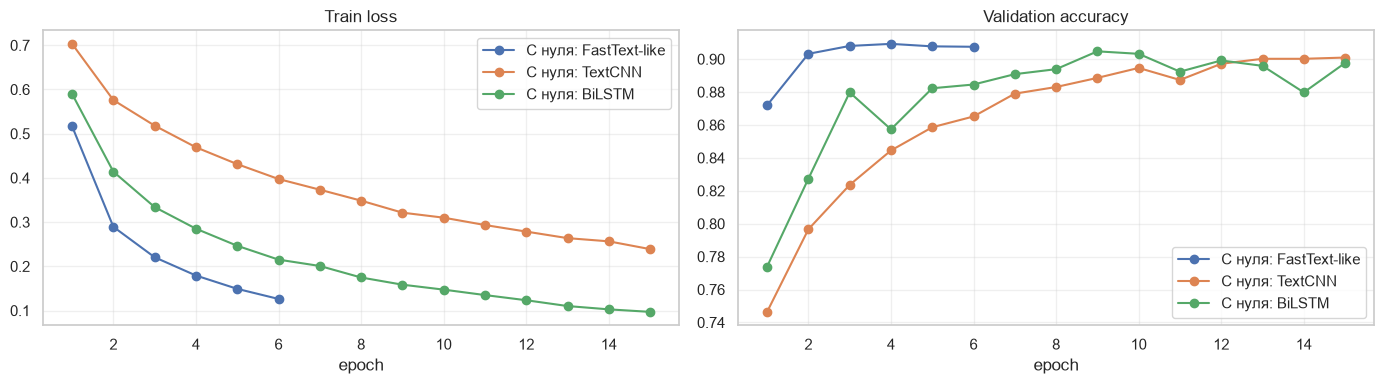

In [7]:
p.plot_histories({n: HISTORIES[n] for n in ["С нуля: FastText-like", "С нуля: TextCNN", "С нуля: BiLSTM"]})

- **FastText-like** обучается за ~14 секунд и быстро переобучается (лучшая эпоха — 4-я, затем ранняя остановка): F1 **0.904** — на уровне TF-IDF с биграммами.
- **TextCNN** и **BiLSTM** со случайной инициализацией сходятся медленно. С бюджетом 15 эпох TextCNN дошла до F1 **0.895** (лучшая эпоха — последняя, валидация ещё немного росла), BiLSTM — до **0.893** (лучшая эпоха 12-я, дальше колебания и ранняя остановка; ~13 минут). Обе модели всё равно чуть уступают бейзлайну TF-IDF + LogReg (0.896): выучить хорошие эмбеддинги с нуля на 36 тыс. отзывов трудно.

## 3. Готовые эмбеддинги: GloVe 6B (300d)

Векторы GloVe (Wikipedia + Gigaword, 400 тыс. слов, 300 измерений) берём из HuggingFace Hub (`sentence-transformers/average_word_embeddings_glove.6B.300d`) — `core.utils.load_glove_from_hub` вместо ручного скачивания архива (как `load_glove_fixed_vocab` в шаблоне).

1. **Усреднённый GloVe-вектор отзыва + LogReg** — эмбеддинги «как есть», без обучения сети (усредняются только слова, найденные в GloVe).
2. **TextCNN и BiLSTM с инициализацией слоя эмбеддингов векторами GloVe** (дообучаются вместе с сетью). Слова, которых нет в GloVe, инициализируются случайно.

In [8]:
glove_index, glove_weights = load_glove_from_hub()
GLOVE_DIM = glove_weights.shape[1]
emb_matrix, in_glove = build_embedding_matrix(seq_vec.token_to_id_, glove_index, glove_weights, seed=SEED)
used = ids_tr[ids_tr != 0]
token_cov = in_glove[torch.as_tensor(used)].float().mean().item()
print(f"слов словаря найдено в GloVe: {in_glove.sum().item() / (V - 2):.1%}; "
      f"доля употреблений (включая <OOV>) с вектором GloVe: {token_cov:.1%}")
# полная матрица GloVe (400k × 300) больше не нужна — оставляем только строки нашего словаря
del glove_index, glove_weights, used
free_memory()

слов словаря найдено в GloVe: 93.7%; доля употреблений (включая <OOV>) с вектором GloVe: 99.1%


In [9]:
@torch.no_grad()
def mean_glove(ids, batch_size=1024):
    # слова вне GloVe (случайные векторы), PAD и OOV в среднее не берём
    E, keep = emb_matrix.to(DEVICE), in_glove.to(DEVICE)
    out = []
    for i in range(0, len(ids), batch_size):
        b = torch.as_tensor(ids[i:i + batch_size], device=DEVICE)
        mask = keep[b].unsqueeze(-1).float()
        out.append(((E[b] * mask).sum(1) / mask.sum(1).clamp(min=1)).cpu())
    return torch.cat(out).numpy()

t0 = time.time()
G_train, G_test = mean_glove(np.vstack([ids_tr, ids_val])), mean_glove(ids_test)
glove_lr = LogisticRegression(C=1, max_iter=3000).fit(G_train, pd.concat([y_tr, y_val]))
PROBAS["GloVe: усреднение + LogReg"] = glove_lr.predict_proba(G_test)[:, 1]
evaluate_probas(results, "GloVe: усреднение + LogReg", "4. Готовые эмбеддинги", y_test,
                PROBAS["GloVe: усреднение + LogReg"], time.time() - t0)
del G_train, G_test, glove_lr

GloVe: усреднение + LogReg                              acc=0.8370  f1=0.8370  roc_auc=0.9127


In [10]:
glove_cnn = run_nn("GloVe: TextCNN", "4. Готовые эмбеддинги",
                   lambda: TextCNN(V, embedding_dim=GLOVE_DIM, pretrained=emb_matrix), num_epochs=10, patience=2)

epoch 1: train_loss=0.4564  val_acc=0.8873  val_auc=0.9518  (9s)


epoch 2: train_loss=0.2964  val_acc=0.8992  val_auc=0.9636  (19s)


epoch 3: train_loss=0.2317  val_acc=0.9050  val_auc=0.9664  (28s)


epoch 4: train_loss=0.1853  val_acc=0.9047  val_auc=0.9666  (38s)


epoch 5: train_loss=0.1441  val_acc=0.9087  val_auc=0.9661  (48s)


epoch 6: train_loss=0.1126  val_acc=0.9067  val_auc=0.9655  (58s)
ранняя остановка
лучшая эпоха: 4


GloVe: TextCNN                                          acc=0.9009  f1=0.9008  roc_auc=0.9635


epoch 1: train_loss=0.4265  val_acc=0.9019  val_auc=0.9625  (48s)


epoch 2: train_loss=0.2363  val_acc=0.9171  val_auc=0.9702  (95s)


epoch 3: train_loss=0.1595  val_acc=0.9191  val_auc=0.9715  (141s)


epoch 4: train_loss=0.1016  val_acc=0.9150  val_auc=0.9704  (187s)


epoch 5: train_loss=0.0639  val_acc=0.9085  val_auc=0.9677  (233s)
ранняя остановка
лучшая эпоха: 3


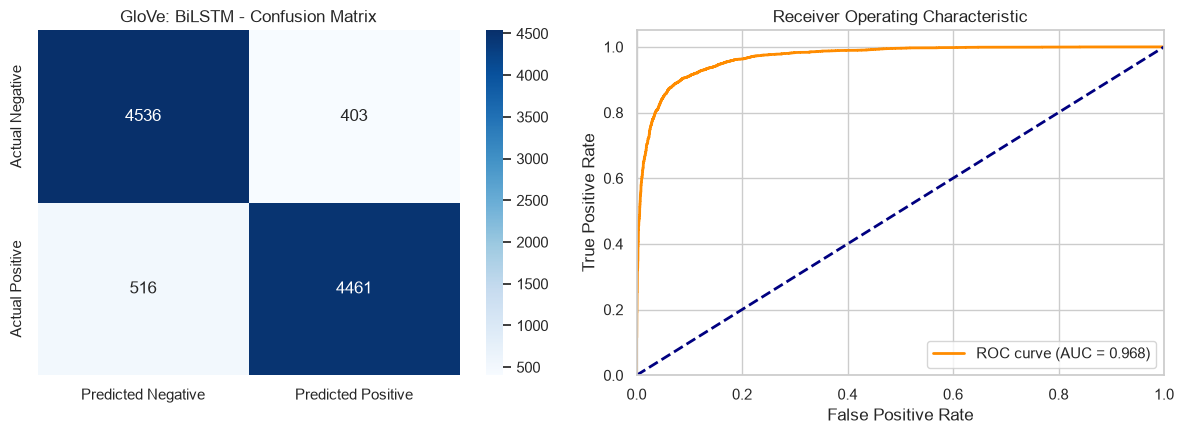


                  GLOVE: BILSTM EVALUATION                  

MAIN METRICS:
   Metric  Value
  ROC AUC 0.9679
 F1 Score 0.9073
Precision 0.9075
   Recall 0.9074
 Accuracy 0.9073


CLASSIFICATION REPORT:
   Class  Precision   Recall
Positive   0.917146 0.896323
Negative   0.897862 0.918405

GloVe: BiLSTM                                           acc=0.9073  f1=0.9073  roc_auc=0.9679


In [11]:
glove_lstm = run_nn("GloVe: BiLSTM", "4. Готовые эмбеддинги",
                    lambda: BiLSTM(V, embedding_dim=GLOVE_DIM, pretrained=emb_matrix), num_epochs=10, patience=2,
                    enable_plot=True)
del glove_cnn, glove_lstm
free_memory()

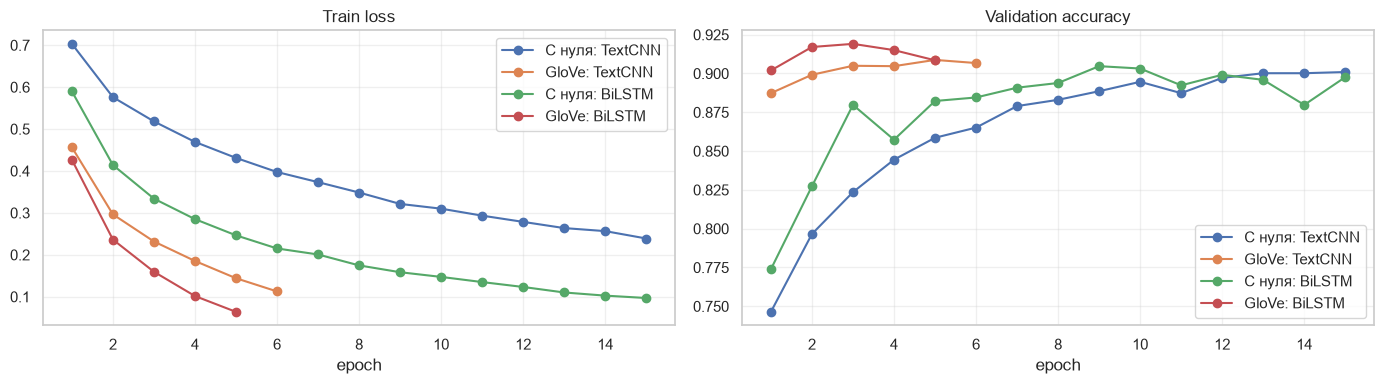

In [12]:
p.plot_histories({n: HISTORIES[n] for n in ["С нуля: TextCNN", "GloVe: TextCNN", "С нуля: BiLSTM", "GloVe: BiLSTM"]})

- Простое усреднение GloVe-векторов заметно хуже TF-IDF (F1 0.837): при усреднении теряется информация о редких, но сильных маркерах тональности, а сами векторы GloVe обучались не под тональность (*good* и *bad* в них близки — встречаются в похожих контекстах).
- Зато как **инициализация** GloVe сильно помогает: TextCNN 0.895 → **0.901**, BiLSTM 0.893 → **0.907**. Сети стартуют с осмысленных векторов: уже после 1-й эпохи val accuracy ~0.89–0.90 (против ~0.75 с нуля), лучшая эпоха — 3–4-я вместо 12–15-й, и BiLSTM учится в ~3 раза быстрее (233 с против 771 с).

## 4. Предобученные модели

1. **Sentence-Transformers `all-MiniLM-L6-v2`** — замороженный трансформер как извлекатель признаков (эмбеддинг всего отзыва, 384d) + LogReg.
2. **Fine-tuning `distilbert-base-uncased`** — `BertVectorizer` и `BertClassifier` (трансформер + линейная голова на `[CLS]`) из шаблона; дообучаем все 66M параметров: до 3 эпох с выбором лучшей по валидации, `max_len=256`, AdamW, lr = 2e-5, линейный warmup/decay, bf16.

In [13]:
from sentence_transformers import SentenceTransformer

t0 = time.time()
st_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=str(DEVICE))
st_model.max_seq_length = 256
S_train = st_model.encode(X_train.tolist(), batch_size=128, show_progress_bar=False)
S_test = st_model.encode(X_test.tolist(), batch_size=128, show_progress_bar=False)
st_lr = LogisticRegression(C=1, max_iter=3000).fit(S_train, y_train)
PROBAS["Pretrained: MiniLM-L6 эмбеддинги + LogReg"] = st_lr.predict_proba(S_test)[:, 1]
evaluate_probas(results, "Pretrained: MiniLM-L6 эмбеддинги + LogReg", "5. Предобученные", y_test,
                PROBAS["Pretrained: MiniLM-L6 эмбеддинги + LogReg"], time.time() - t0)
del st_model, S_train, S_test, st_lr
free_memory()

Pretrained: MiniLM-L6 эмбеддинги + LogReg               acc=0.8132  f1=0.8132  roc_auc=0.8971


epoch 1: train_loss=0.2944  val_acc=0.9178  val_auc=0.9731  (173s)


epoch 2: train_loss=0.1654  val_acc=0.9156  val_auc=0.9768  (353s)


epoch 3: train_loss=0.1033  val_acc=0.9254  val_auc=0.9763  (540s)
ранняя остановка
лучшая эпоха: 2


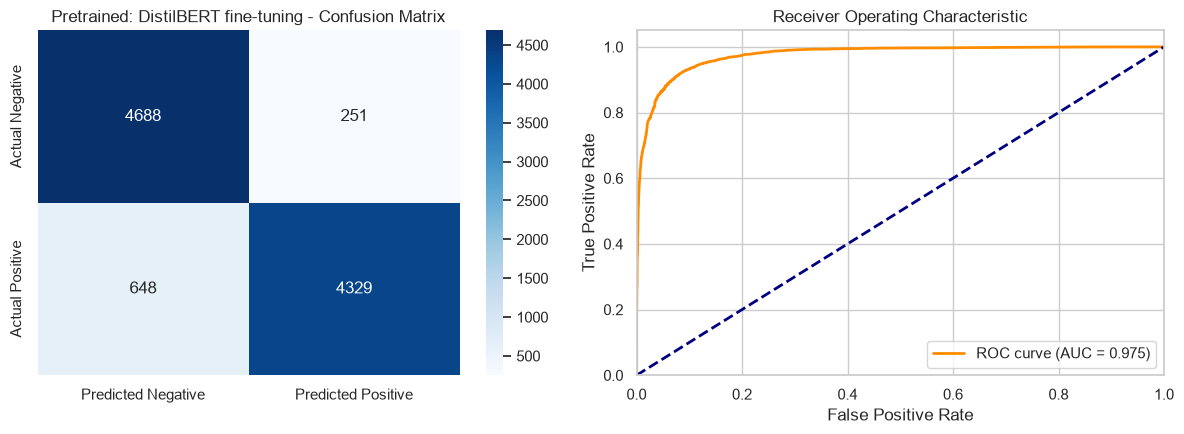


       PRETRAINED: DISTILBERT FINE-TUNING EVALUATION        

MAIN METRICS:
   Metric  Value
  ROC AUC 0.9747
 F1 Score 0.9092
Precision 0.9119
   Recall 0.9095
 Accuracy 0.9093


CLASSIFICATION REPORT:
   Class  Precision   Recall
Positive   0.945197 0.869801
Negative   0.878561 0.949180

Pretrained: DistilBERT fine-tuning                      acc=0.9093  f1=0.9092  roc_auc=0.9747


In [14]:
BERT_NAME, BERT_LEN = "distilbert-base-uncased", 256
bert_vec = BertVectorizer(BERT_NAME, max_length=BERT_LEN).fit(X_tr)
bids_tr, bids_val, bids_test = (bert_vec.transform(X) for X in (X_tr, X_val, X_test))

init_random_seed(SEED)
bert, bert_hist, bert_time = train_model(
    BertClassifier(BERT_NAME, pad_token_id=bert_vec.tokenizer_.pad_token_id), bids_tr, y_tr, bids_val, y_val,
    num_epochs=3, batch_size=32, lr=2e-5, weight_decay=0.01, patience=1, warmup_ratio=0.06, use_amp=True, device=DEVICE)
PROBAS["Pretrained: DistilBERT fine-tuning"] = predict_proba(bert, bids_test, device=DEVICE, use_amp=True)
evaluate_probas(results, "Pretrained: DistilBERT fine-tuning", "5. Предобученные", y_test,
                PROBAS["Pretrained: DistilBERT fine-tuning"], bert_time, enable_plot=True)
del bert, bids_tr, bids_val, bids_test
free_memory()

- **DistilBERT** — лучший ROC-AUC среди всех моделей (**0.975**; на валидации 0.977, выбрана 2-я эпоха), но F1 при пороге 0.5 — **0.909**, ниже TF-IDF + χ² (0.918). По отчёту видно, что модель сдвинута в сторону негатива: recall положительного класса 0.87 против 0.95 у отрицательного. Ранняя остановка выбирает эпоху по ROC-AUC, который не зависит от порога, поэтому подбор порога на валидации, скорее всего, подтянул бы F1. Ещё одно ограничение — модель видит только первые 256 субтокенов (итоговая оценка в длинных отзывах часто в конце). Обучение заняло ~9 минут на GPU — в ~20 раз дольше лучшей линейной модели.
- **Замороженные эмбеддинги MiniLM** — худший результат (F1 0.813): универсальная модель семантической близости предложений не заточена под тональность, и одного вектора на весь отзыв недостаточно.

## 5. Итоговое сравнение

Объединяем результаты этого ноутбука с `results/baseline_results.csv` и сохраняем общую таблицу в `results.csv`.

In [15]:
baseline_df = pd.read_csv("results/baseline_results.csv", index_col="Model")
summary = pd.concat([baseline_df, results.to_dataframe()]).sort_values("F1 Score", ascending=False)
summary.index.name = "Model"
summary["Training Time (s)"] = summary["Training Time (s)"].round(1)
summary.to_csv("results.csv")
summary.style.format({c: "{:.4f}" for c in ["ROC AUC", "F1 Score", "Precision", "Recall", "Accuracy"]}
                     ).format({"Training Time (s)": "{:.1f}"}).background_gradient(subset=["F1 Score"], cmap="Greens")

,Group,ROC AUC,F1 Score,Precision,Recall,Accuracy,Training Time (s)
Model,,,,,,,
TF-IDF 1-2-граммы + χ² (k=227442) + LogReg C=10,2. Отбор токенов,0.973079,0.918310,0.918336,0.918301,0.918314,25.7
Pretrained: DistilBERT fine-tuning,5. Предобученные,0.974731,0.909219,0.911879,0.909491,0.909338,540.3
GloVe: BiLSTM,4. Готовые эмбеддинги,0.967930,0.907316,0.907504,0.907364,0.907322,233.3
TF-IDF 1-2-граммы,2. Отбор токенов,0.967182,0.905599,0.905667,0.905585,0.905607,21.1
С нуля: FastText-like,3. NN с нуля,0.963457,0.903970,0.904241,0.903947,0.903994,13.6
GloVe: TextCNN,4. Готовые эмбеддинги,0.963456,0.900834,0.901612,0.900951,0.900867,58.1
"TF-IDF min_df=3, max_df=0.9, sublinear_tf",2. Отбор токенов,0.962447,0.899449,0.899494,0.899437,0.899455,6.7
Baseline: TF-IDF + LogReg,1. Бейзлайн,0.961054,0.896210,0.896387,0.896191,0.896228,7.7
С нуля: TextCNN,3. NN с нуля,0.960840,0.894808,0.894864,0.894796,0.894816,93.4


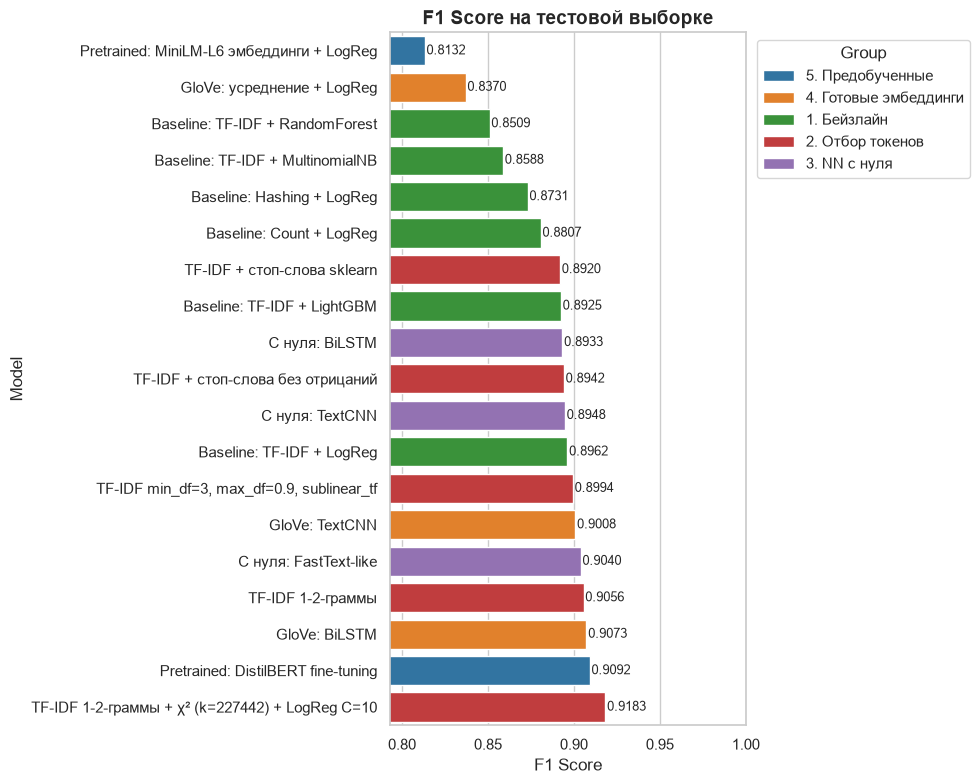

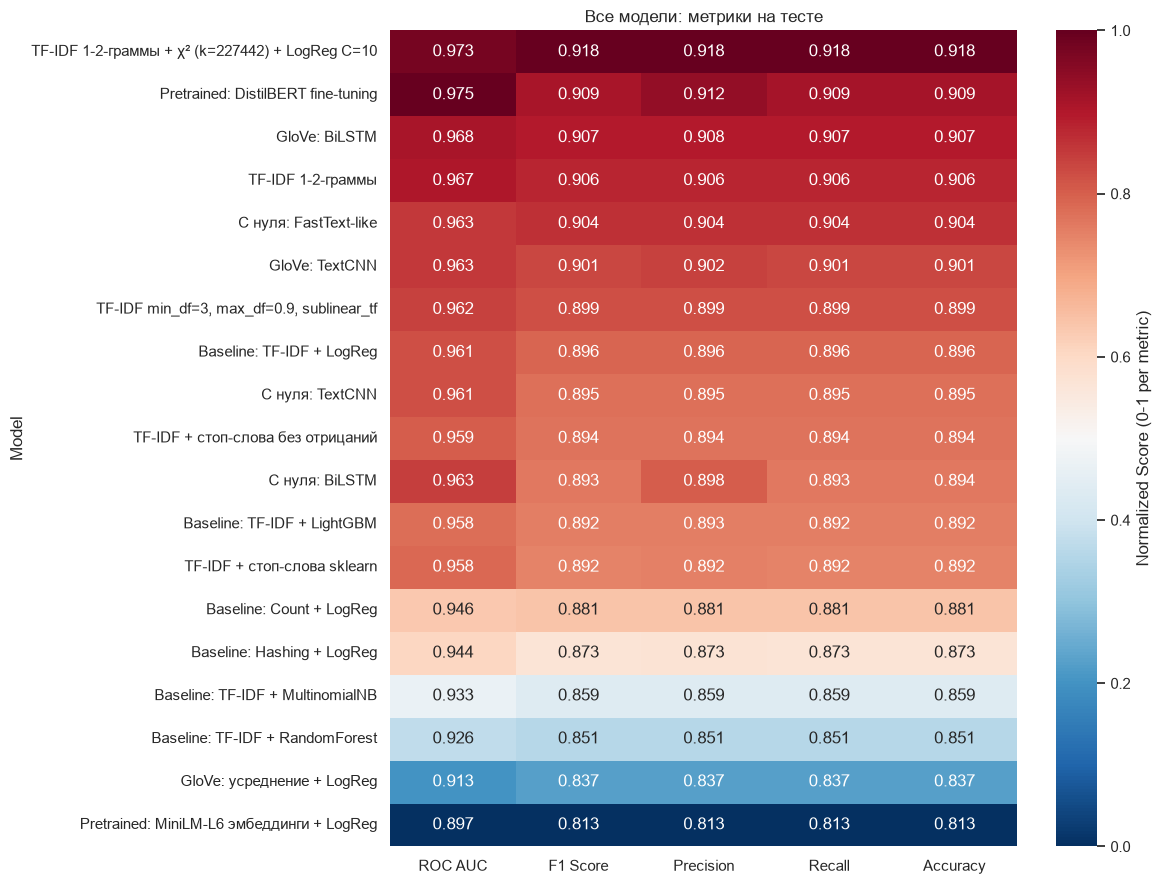

,Model,F1 Score,ROC AUC,Training Time (s)
Group,,,,
1. Бейзлайн,Baseline: TF-IDF + LogReg,0.8962,0.9611,7.7
2. Отбор токенов,TF-IDF 1-2-граммы + χ² (k=227442) + LogReg C=10,0.9183,0.9731,25.7
3. NN с нуля,С нуля: FastText-like,0.9040,0.9635,13.6
4. Готовые эмбеддинги,GloVe: BiLSTM,0.9073,0.9679,233.3
5. Предобученные,Pretrained: DistilBERT fine-tuning,0.9092,0.9747,540.3


In [16]:
p.plot_models_bar(summary, "F1 Score")
p.plot_metrics_heatmap(summary.drop(columns=["Training Time (s)"]), title="Все модели: метрики на тесте", figsize=(12, 9))
best_per_group = summary.reset_index().sort_values("F1 Score", ascending=False).groupby("Group").head(1).set_index("Group").sort_index()
best_per_group[["Model", "F1 Score", "ROC AUC", "Training Time (s)"]].round(4)

### Анализ ошибок лучшей модели

Лучшая по F1 модель определяется по итоговой таблице. Если это линейная модель из `baseline.ipynb`, её вероятности на тесте читаются из `results/proba_best_linear.csv`.

лучшая модель по F1: TF-IDF 1-2-граммы + χ² (k=227442) + LogReg C=10


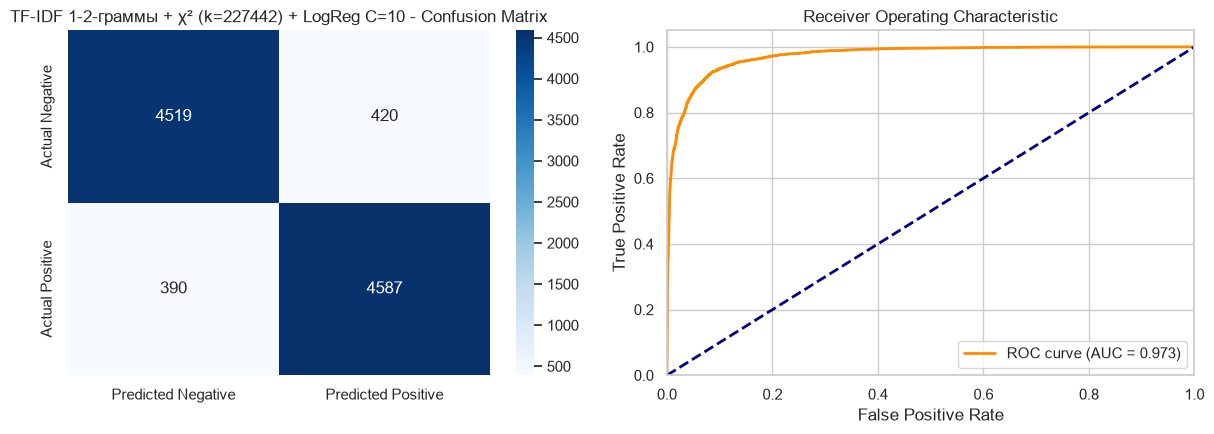


 TF-IDF 1-2-ГРАММЫ + Χ² (K=227442) + LOGREG C=10 EVALUATION 

MAIN METRICS:
   Metric  Value
  ROC AUC 0.9731
 F1 Score 0.9183
Precision 0.9183
   Recall 0.9183
 Accuracy 0.9183


CLASSIFICATION REPORT:
   Class  Precision   Recall
Positive   0.916117 0.921640
Negative   0.920554 0.914963


ошибок: 810; самые уверенные из них:

true=0  proba_pos=0.998
Mickey Rourke hunts Diane Lane in Elmore Leonard's Killshot It is not like Mickey Rourke ever really disappeared. He has had a steady string of appearances before he burst back on the scene. He was memorable in: Domino, Sin City, Man on Fire, Once Upon a Time in Mexico, and Get Carter. But in his powerful dramatic performance in The Wrestler (2008), we see a full blown presentation of the character only hinted at in Get Carter. Whenever we get to know him, Rourke remains a cool, but sleazy, muscle bound slim ball.  This is an Elmore Leonard story, and production. Leonard wrote such notable mov...

true=1  proba_pos=0.004
This movie is st

In [17]:
best_linear = pd.read_csv("results/proba_best_linear.csv", index_col=0)
assert (best_linear.index == y_test.index).all(), "разбиение в ноутбуках должно совпадать"
with open("results/best_linear_name.txt", encoding="utf-8") as f:
    PROBAS[f.read().strip()] = best_linear["proba"].values

BEST_NAME = summary.index[0]
best_proba = PROBAS[BEST_NAME]
print("лучшая модель по F1:", BEST_NAME)
best_metrics = evaluate_classification(y_test, (best_proba >= 0.5).astype(int), best_proba, BEST_NAME)

errors = pd.DataFrame({"review": X_test.values, "true": y_test.values, "proba": best_proba})
errors = errors[(errors["proba"] >= 0.5) != errors["true"].astype(bool)]
errors["conf"] = (errors["proba"] - 0.5).abs()
print(f"\nошибок: {len(errors)}; самые уверенные из них:\n")
for _, r in errors.sort_values("conf", ascending=False).head(4).iterrows():
    print(f"true={r['true']}  proba_pos={r['proba']:.3f}\n{r['review'][:600]}...\n")

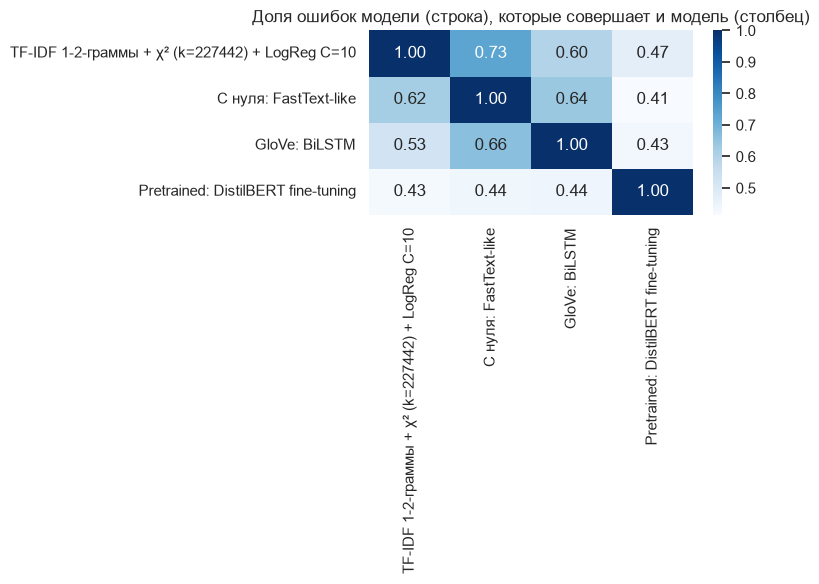

In [18]:
# Насколько ошибки лучшей модели совпадают с ошибками остальных групп
err = {n: (PROBAS[n] >= 0.5) != y_test.values for n in best_per_group["Model"] if n in PROBAS}
names = list(err)
overlap = pd.DataFrame([[(err[a] & err[b]).sum() / max(err[a].sum(), 1) for b in names] for a in names],
                       index=names, columns=names)
plt.figure(figsize=(8, 6))
sns.heatmap(overlap, annot=True, fmt=".2f", cmap="Blues")
plt.title("Доля ошибок модели (строка), которые совершает и модель (столбец)")
plt.tight_layout()
plt.show()

- Лучшая модель (TF-IDF + χ²) ошибается на 810 из 9 916 отзывов (8.2%), ошибки симметричны по классам.
- Самые уверенные ошибки — отзывы, где тональность выражена не оценочными словами. Пример: положительный отзыв на трэш-хоррор, который перечисляет «incredibly awful score», «worst Foley work» и хвалит фильм как развлечение. Обратный случай: отзывы с меткой negative, полные похвал (*great writing… must see*), — скорее всего, шум в разметке.
- Ошибки моделей «мешка слов» сильно пересекаются: 73% ошибок линейной модели повторяет FastText-like. У DistilBERT только 41–47% ошибок общие с остальными моделями. Модели ошибаются по-разному, поэтому ансамбль TF-IDF + DistilBERT — перспективное улучшение.

## 6. Выводы

| Группа | Лучшая модель | F1 | ROC-AUC | Время обучения |
|---|---|---|---|---|
| 1. Бейзлайн | TF-IDF + LogReg | 0.896 | 0.961 | 8 с |
| 2. Отбор токенов | TF-IDF 1-2-граммы + χ² (k ≈ 227 тыс.) + LogReg C=10 | **0.918** | 0.973 | 26 с |
| 3. NN с нуля | FastText-like | 0.904 | 0.963 | 14 с |
| 4. Готовые эмбеддинги | GloVe + BiLSTM | 0.907 | 0.968 | 233 с |
| 5. Предобученные | DistilBERT fine-tuning | 0.909 | **0.975** | 540 с |

Полная таблица из 19 моделей — в `results.csv`.

1. **Задача хорошо решается «мешком слов».** Простой TF-IDF + логистическая регрессия даёт F1 ≈ 0.90: отзывы IMDB длинные и содержат явные оценочные слова. Из классических алгоритмов линейная модель лучше LightGBM, наивного Байеса и случайного леса.
2. **Отбор токенов даёт прирост ~2 п.п.**: главное — биграммы, сублинейный TF и отбор признаков по χ² с подбором регуляризации. Удаление стоп-слов, наоборот, вредит — оно выкидывает отрицания.
3. **Нейросети с нуля** на 36 тыс. отзывов не превосходят линейную модель на n-граммах. Лучшая из них — самая простая (FastText-like). TextCNN и BiLSTM без предобученных эмбеддингов сходятся медленно (12–15 эпох).
4. **Готовые эмбеддинги GloVe** при простом усреднении слабы (0.837), но как инициализация улучшают сети (+0.6–1.4 п.п. F1) и ускоряют их сходимость в 3–4 раза.
5. **Дообученный DistilBERT** — лучший по ROC-AUC (0.975), но по F1 при пороге 0.5 уступает лучшей линейной модели и учится в ~20 раз дольше. Замороженные sentence-эмбеддинги без дообучения — худший вариант.
6. **Ошибки** лучшей модели — в основном отзывы со смешанной или «ироничной» тональностью и, вероятно, шум в разметке. Ошибки DistilBERT мало пересекаются с ошибками моделей «мешка слов».

**Что можно улучшить:** подобрать порог классификации DistilBERT на валидации и учитывать конец отзыва (head+tail truncation); ансамбль TF-IDF + χ² и DistilBERT (модели ошибаются по-разному); дать TextCNN с нуля ещё больше эпох.